In [1]:
# =====================================================================
# NHIỆM VỤ 1: TẢI VÀ MÔ TẢ TẬP DỮ LIỆU BẰNG PYTHON
# =====================================================================
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13})

# Bảng màu thống nhất cho toàn bộ notebook
COL_STAY = "#1F4E79"     # xanh navy -> Existing Customer (0)
COL_LEAVE = "#C0392B"    # đỏ        -> Attrited Customer (1)
LABELS = {0: "Existing Customer", 1: "Attrited Customer"}
HUE_ORDER = ["Existing Customer", "Attrited Customer"]
PAL = {"Existing Customer": COL_STAY, "Attrited Customer": COL_LEAVE}

# Đọc dữ liệu (đặt file CSV cùng thư mục với notebook)
df = pd.read_csv("BankChurners_clean.csv")

# Bản sao dùng riêng cho vẽ biểu đồ (nhãn chữ thay cho 0/1), df gốc giữ nguyên
plot_df = df.assign(Group=df["Attrition_Flag"].map(LABELS))

print("Kích thước tập dữ liệu (shape):", df.shape)
print(f"-> {df.shape[0]:,} dòng (khách hàng) x {df.shape[1]} cột (thuộc tính)\n")

print("5 dòng đầu tiên (df.head()):")
display(df.head())

print("\nDanh sách thuộc tính:")
for i, col in enumerate(df.columns, start=1):
    print(f"{i:>2}. {col}")

Kích thước tập dữ liệu (shape): (10127, 21)
-> 10,127 dòng (khách hàng) x 21 cột (thuộc tính)

5 dòng đầu tiên (df.head()):


,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio
0,768805383,0,45,M,3,High School,Married,$60K - $80K,Blue,39,5,1,3,12691.0,777,11914.0,1.335,1144,42,1.625,0.061
1,818770008,0,49,F,5,Graduate,Single,Less than $40K,Blue,44,6,1,2,8256.0,864,7392.0,1.541,1291,33,3.714,0.105
2,713982108,0,51,M,3,Graduate,Married,$80K - $120K,Blue,36,4,1,0,3418.0,0,3418.0,2.594,1887,20,2.333,0.000
3,769911858,0,40,F,4,High School,Unknown,Less than $40K,Blue,34,3,4,1,3313.0,2517,796.0,1.405,1171,20,2.333,0.760
4,709106358,0,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,5,1,0,4716.0,0,4716.0,2.175,816,28,2.500,0.000



Danh sách thuộc tính:
 1. CLIENTNUM
 2. Attrition_Flag
 3. Customer_Age
 4. Gender
 5. Dependent_count
 6. Education_Level
 7. Marital_Status
 8. Income_Category
 9. Card_Category
10. Months_on_book
11. Total_Relationship_Count
12. Months_Inactive_12_mon
13. Contacts_Count_12_mon
14. Credit_Limit
15. Total_Revolving_Bal
16. Avg_Open_To_Buy
17. Total_Amt_Chng_Q4_Q1
18. Total_Trans_Amt
19. Total_Trans_Ct
20. Total_Ct_Chng_Q4_Q1
21. Avg_Utilization_Ratio


# Khám phá, Phân tích, Trực quan hóa và Diễn giải Dữ liệu — Khách hàng thẻ tín dụng (BankChurners)
**Môn học:** Data Science with Python (ADY) &nbsp;|&nbsp; **Công cụ:** pandas, numpy, matplotlib, seaborn

---
## Nhiệm vụ 1 — Mô tả tổng quan tập dữ liệu

**Bối cảnh.** Tập dữ liệu mô tả danh mục khách hàng thẻ tín dụng của một ngân hàng. Mỗi dòng là một chủ thẻ, gồm thông tin nhân khẩu học, đặc điểm thẻ và hành vi sử dụng/giao dịch trong 12 tháng gần nhất. Bài toán nghiệp vụ là **churn (khách hàng rời bỏ)**: nhận diện những yếu tố phân biệt khách hàng đóng thẻ với khách hàng tiếp tục sử dụng để ngân hàng có thể giữ chân sớm.

**Quy mô.** 10.127 quan sát và 21 cột, gồm: 1 mã định danh (`CLIENTNUM`), 1 biến mục tiêu (`Attrition_Flag`) và 19 đặc trưng. Tệp đã được làm sạch ở giai đoạn trước.

**Biến mục tiêu.** `Attrition_Flag` được mã hóa nhị phân: **0 = Existing Customer** (còn sử dụng thẻ), **1 = Attrited Customer** (đã rời bỏ).

| Nhóm đặc trưng | Các cột |
|---|---|
| Nhân khẩu học | `Customer_Age`, `Gender`, `Dependent_count`, `Education_Level`, `Marital_Status`, `Income_Category` |
| Thẻ và quan hệ với ngân hàng | `Card_Category`, `Months_on_book`, `Total_Relationship_Count` |
| Tương tác và mức độ hoạt động | `Months_Inactive_12_mon`, `Contacts_Count_12_mon` |
| Tài chính và hành vi giao dịch | `Credit_Limit`, `Total_Revolving_Bal`, `Avg_Open_To_Buy`, `Total_Amt_Chng_Q4_Q1`, `Total_Trans_Amt`, `Total_Trans_Ct`, `Total_Ct_Chng_Q4_Q1`, `Avg_Utilization_Ratio` |

**Biến phân hóa trọng tâm:** `Total_Trans_Ct` (tổng số lượt giao dịch thẻ trong năm). Các phần sau sẽ kiểm chứng vai trò của biến này.

*Lưu ý:* `CLIENTNUM` chỉ là mã khách hàng, không mang ý nghĩa phân tích nên được loại khỏi các thống kê mô tả và tính tương quan.

In [2]:
# =====================================================================
# NHIỆM VỤ 2: KIỂM TRA CHẤT LƯỢNG DỮ LIỆU
# =====================================================================

# 1) Dữ liệu khuyết thiếu ------------------------------------------------
print("=" * 70)
print("1) DỮ LIỆU KHUYẾT THIẾU (NULL)")
print("=" * 70)
n_null = df.isnull().sum()
print(f"Tổng số ô null: {int(n_null.sum())} | Số cột có null: {int((n_null > 0).sum())}")

# 2) Bản ghi trùng lặp ----------------------------------------------------
print("\n" + "=" * 70)
print("2) BẢN GHI TRÙNG LẶP")
print("=" * 70)
n_dup_rows = int(df.duplicated().sum())
n_dup_id = int(df["CLIENTNUM"].duplicated().sum())
print(f"Số dòng trùng lặp hoàn toàn : {n_dup_rows}")
print(f"Số CLIENTNUM bị lặp         : {n_dup_id}  (CLIENTNUM duy nhất: {df['CLIENTNUM'].is_unique})")

# 3) Kiểu dữ liệu ----------------------------------------------------------
print("\n" + "=" * 70)
print("3) KIỂU DỮ LIỆU (DTYPES) CỦA TỪNG CỘT")
print("=" * 70)
schema = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_null": n_null,
    "n_unique": df.nunique(),
})
display(schema)
print("Tóm tắt kiểu dữ liệu:")
print(df.dtypes.astype(str).value_counts().to_string())

# 4) Tính hợp lệ cận biên --------------------------------------------------
print("\n" + "=" * 70)
print("4) KIỂM TRA CẬN BIÊN TRÊN CÁC CỘT SỐ TRỌNG TÂM")
print("=" * 70)
core_cols = ["Customer_Age", "Credit_Limit", "Total_Trans_Amt", "Total_Trans_Ct"]
bounds = df[core_cols].agg(["min", "max"]).T
bounds["Số giá trị âm"] = (df[core_cols] < 0).sum()
bounds["Số giá trị = 0"] = (df[core_cols] == 0).sum()
display(bounds)
n_neg_all = int((df.select_dtypes("number") < 0).sum().sum())
print(f"Tổng số giá trị âm trên TOÀN BỘ cột số: {n_neg_all}")

# 5) Nhãn 'Unknown' ở biến phân loại (khác với null) --------------------------
cat_cols = list(df.select_dtypes(exclude="number").columns)
unknown_counts = {c: int((df[c] == "Unknown").sum()) for c in cat_cols if (df[c] == "Unknown").any()}
print("\nSố bản ghi mang nhãn 'Unknown' (mức phân loại hợp lệ, không phải null):")
for c, n in unknown_counts.items():
    print(f"  - {c:<16}: {n:>5,} ({n / len(df) * 100:.1f}%)")

1) DỮ LIỆU KHUYẾT THIẾU (NULL)
Tổng số ô null: 0 | Số cột có null: 0

2) BẢN GHI TRÙNG LẶP
Số dòng trùng lặp hoàn toàn : 0
Số CLIENTNUM bị lặp         : 0  (CLIENTNUM duy nhất: True)

3) KIỂU DỮ LIỆU (DTYPES) CỦA TỪNG CỘT


,dtype,n_null,n_unique
CLIENTNUM,int64,0,10127
Attrition_Flag,int64,0,2
Customer_Age,int64,0,45
Gender,str,0,2
Dependent_count,int64,0,6
Education_Level,str,0,7
Marital_Status,str,0,4
Income_Category,str,0,6
Card_Category,str,0,4
Months_on_book,int64,0,44


Tóm tắt kiểu dữ liệu:
int64      11
str         5
float64     5

4) KIỂM TRA CẬN BIÊN TRÊN CÁC CỘT SỐ TRỌNG TÂM


,min,max,Số giá trị âm,Số giá trị = 0
Customer_Age,26.0,73.0,0,0
Credit_Limit,1438.3,34516.0,0,0
Total_Trans_Amt,510.0,18484.0,0,0
Total_Trans_Ct,10.0,139.0,0,0


Tổng số giá trị âm trên TOÀN BỘ cột số: 0

Số bản ghi mang nhãn 'Unknown' (mức phân loại hợp lệ, không phải null):
  - Education_Level : 1,519 (15.0%)
  - Marital_Status  :   749 (7.4%)
  - Income_Category : 1,112 (11.0%)


### Nhận xét chất lượng dữ liệu

| Tiêu chí | Kết quả kiểm tra | Đánh giá |
|---|---|---|
| Giá trị khuyết thiếu (null) | 0 ô null trên toàn bộ 21 cột | Đạt |
| Bản ghi trùng lặp | 0 dòng trùng; `CLIENTNUM` duy nhất cho 10.127 dòng | Đạt |
| Kiểu dữ liệu | 11 cột số nguyên, 5 cột số thực, 5 cột phân loại (văn bản) | Phù hợp ngữ nghĩa từng biến |
| Cận biên `Customer_Age` | 26 đến 73 tuổi | Hợp lý (chủ thẻ trưởng thành) |
| Cận biên `Credit_Limit` | 1438.3 đến 34516 | Dương, không có giá trị bất thường |
| Cận biên `Total_Trans_Amt` | 510 đến 18484 | Dương, không có giá trị bất thường |
| Cận biên `Total_Trans_Ct` | 10 đến 139 lượt/năm | Dương, không có giá trị bất thường |
| Giá trị âm vô lý | 0 trên toàn bộ cột số | Đạt |

**Kết luận.** Dữ liệu đã qua tiền xử lý đạt chuẩn ở mọi tiêu chí kiểm tra: không có null, không có bản ghi trùng lặp, kiểu dữ liệu đúng và các biến số trọng tâm nằm trong miền giá trị hợp lý. Tập dữ liệu sẵn sàng cho phân tích chuyên sâu.

**Một lưu ý cần ghi nhận.** Ba biến phân loại có nhãn `Unknown`: `Education_Level` (1.519 dòng), `Marital_Status` (749 dòng) và `Income_Category` (1.112 dòng). Đây là **mức phân loại hợp lệ** (khách hàng không khai báo thông tin), không phải null nên không vi phạm kết luận ở trên. Notebook giữ nguyên chúng như một nhóm riêng; cách xử lý (giữ làm một mức, hoặc gán giá trị) sẽ được quyết định ở giai đoạn xây dựng mô hình.

In [3]:
# =====================================================================
# NHIỆM VỤ 3: THỐNG KÊ MÔ TẢ
# =====================================================================

# 3.1 Thống kê mô tả cho các biến định lượng (loại CLIENTNUM và biến mục tiêu)
num_cols = [c for c in df.select_dtypes("number").columns if c not in ("CLIENTNUM", "Attrition_Flag")]

desc = df[num_cols].describe().T.rename(columns={"50%": "median"})
desc["IQR"] = desc["75%"] - desc["25%"]                 # khoảng tứ phân vị
desc["CV (%)"] = desc["std"] / desc["mean"] * 100       # hệ số biến thiên
desc["skew"] = df[num_cols].skew()                      # độ lệch
desc = desc[["count", "mean", "std", "median", "min", "max", "IQR", "CV (%)", "skew"]].round(2)

print("3.1 THỐNG KÊ MÔ TẢ CÁC BIẾN ĐỊNH LƯỢNG")
display(desc)

# 3.2 Bảng tần suất và tỷ lệ phần trăm cho biến mục tiêu và biến phân loại chính
def freq_table(series, name):
    t = series.value_counts().rename_axis(name).to_frame("Số lượng")
    t["Tỷ lệ (%)"] = (t["Số lượng"] / len(series) * 100).round(2)
    return t

print("\n3.2 PHÂN BỐ BIẾN MỤC TIÊU: Attrition_Flag")
display(freq_table(df["Attrition_Flag"].map(LABELS), "Attrition_Flag"))

for col in ["Gender", "Card_Category", "Income_Category"]:
    print(f"\nPhân bố biến phân loại: {col}")
    display(freq_table(df[col], col))

vc = df["Attrition_Flag"].value_counts()
print(f"\nTỷ lệ mất cân bằng (Existing : Attrited) = {vc[0] / vc[1]:.2f} : 1")

3.1 THỐNG KÊ MÔ TẢ CÁC BIẾN ĐỊNH LƯỢNG


,count,mean,std,median,min,max,IQR,CV (%),skew
Customer_Age,10127.0,46.33,8.02,46.00,26.0,73.00,11.00,17.31,-0.03
Dependent_count,10127.0,2.35,1.30,2.00,0.0,5.00,2.00,55.36,-0.02
Months_on_book,10127.0,35.93,7.99,36.00,13.0,56.00,9.00,22.23,-0.11
Total_Relationship_Count,10127.0,3.81,1.55,4.00,1.0,6.00,2.00,40.77,-0.16
Months_Inactive_12_mon,10127.0,2.34,1.01,2.00,0.0,6.00,1.00,43.17,0.63
Contacts_Count_12_mon,10127.0,2.46,1.11,2.00,0.0,6.00,1.00,45.05,0.01
Credit_Limit,10127.0,8631.95,9088.78,4549.00,1438.3,34516.00,8512.50,105.29,1.67
Total_Revolving_Bal,10127.0,1162.81,814.99,1276.00,0.0,2517.00,1425.00,70.09,-0.15
Avg_Open_To_Buy,10127.0,7469.14,9090.69,3474.00,3.0,34516.00,8534.50,121.71,1.66
Total_Amt_Chng_Q4_Q1,10127.0,0.76,0.22,0.74,0.0,3.40,0.23,28.85,1.73



3.2 PHÂN BỐ BIẾN MỤC TIÊU: Attrition_Flag


,Số lượng,Tỷ lệ (%)
Attrition_Flag,,
Existing Customer,8500,83.93
Attrited Customer,1627,16.07



Phân bố biến phân loại: Gender


...


Phân bố biến phân loại: Card_Category


,Số lượng,Tỷ lệ (%)
Card_Category,,
Blue,9436,93.18
Silver,555,5.48
Gold,116,1.15
Platinum,20,0.20



Phân bố biến phân loại: Income_Category


,Số lượng,Tỷ lệ (%)
Income_Category,,
Less than $40K,3561,35.16
$40K - $60K,1790,17.68
$80K - $120K,1535,15.16
$60K - $80K,1402,13.84
Unknown,1112,10.98
$120K +,727,7.18



Tỷ lệ mất cân bằng (Existing : Attrited) = 5.22 : 1


### Nhận xét thống kê mô tả

**1. Độ lệch chuẩn và độ biến thiên.** Để so sánh biến thiên giữa các biến có thang đo khác nhau, ta dùng hệ số biến thiên CV = std / mean:

- **Biến thiên rất lớn (CV khoảng 100% trở lên):** `Credit_Limit` (CV 105%), `Avg_Open_To_Buy` (122%), `Avg_Utilization_Ratio` (100%). `Credit_Limit` có trung bình 8632 cao gần gấp đôi trung vị 4549, độ lệch phải 1.67 và IQR 8512.5. Điều này cho thấy phân phối **lệch phải mạnh**: phần lớn khách hàng có hạn mức thấp, một nhóm nhỏ hạn mức rất cao kéo trung bình lên.
- **Biến thiên lớn:** `Total_Trans_Amt` (CV 77%, trung bình 4404 so với trung vị 3899, độ lệch phải 2.04) và `Total_Revolving_Bal` (CV 70%). Với các biến lệch phải, **trung vị và IQR phản ánh "khách hàng điển hình" tốt hơn trung bình**.
- **Biến thiên vừa phải:** `Total_Trans_Ct` có trung bình 64.86, trung vị 67, std 23.47 (CV 36%) và IQR 36. Trung bình và trung vị gần nhau, độ lệch 0.15 nên phân phối khá cân đối, trải rộng từ 10 đến 139 lượt/năm.
- **Biến thiên thấp:** `Customer_Age` (trung bình 46.33, std 8.02, CV 17%) cho thấy tệp khách hàng khá đồng nhất về độ tuổi.

**2. Mất cân bằng giữa hai nhóm khách hàng.** Có 8.500 khách hàng ở lại (83.93%) và 1.627 khách hàng rời đi (16.07%), tỷ lệ khoảng **5.2 : 1**. Hệ quả: một mô hình "luôn dự đoán ở lại" đã đạt độ chính xác 83.9% mà không phát hiện được khách nào rời đi. Vì vậy ở giai đoạn dự báo cần dùng chia dữ liệu phân tầng (stratified) và các thước đo như Recall, Precision, F1, PR-AUC thay vì chỉ dựa vào Accuracy.

**3. Biến phân loại.**
- `Gender` khá cân bằng (nữ 52.9%, nam 47.1%).
- `Card_Category` **lệch cực mạnh**: hạng Blue chiếm 93.2%, trong khi Platinum chỉ có 20 khách hàng (0.2%). Các so sánh liên quan đến hạng Gold và Platinum có cỡ mẫu nhỏ nên kết luận thống kê kém tin cậy.
- `Income_Category`: nhóm thu nhập thấp nhất chiếm tỷ trọng lớn nhất (35.2%) và 11.0% khách hàng chưa khai báo thu nhập (`Unknown`).

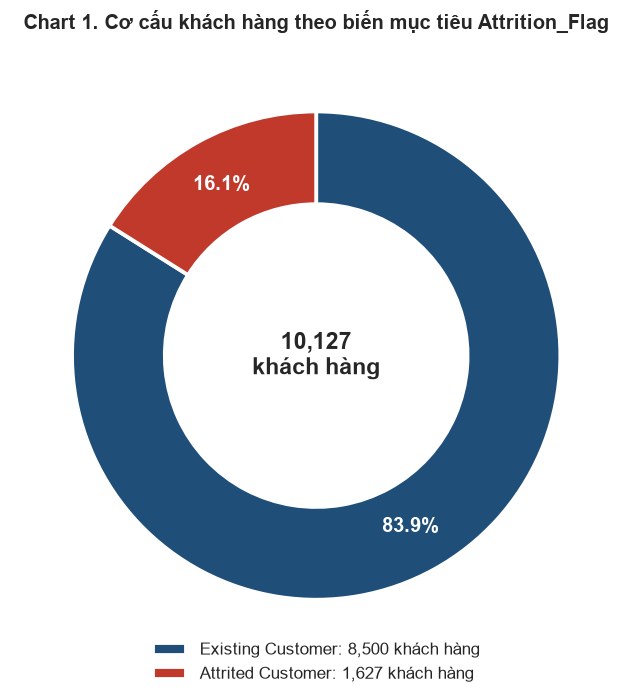

In [4]:
# =====================================================================
# NHIỆM VỤ 4 - CHART 1: PHÂN BỐ BIẾN MỤC TIÊU (DONUT CHART)
# =====================================================================
counts = df["Attrition_Flag"].value_counts().sort_index()      # 0 rồi 1
colors = [PAL[LABELS[i]] for i in counts.index]

fig, ax = plt.subplots(figsize=(7, 6.5))
wedges, texts, autotexts = ax.pie(
    counts.values,
    colors=colors,
    autopct=lambda p: f"{p:.1f}%",
    startangle=90,
    counterclock=False,
    pctdistance=0.80,
    wedgeprops=dict(width=0.38, edgecolor="white", linewidth=2.5),
    textprops=dict(color="white", fontsize=13, fontweight="bold"),
)
ax.text(0, 0, f"{len(df):,}\nkhách hàng", ha="center", va="center", fontsize=15, fontweight="bold")
ax.legend(
    wedges,
    [f"{LABELS[i]}: {n:,} khách hàng" for i, n in counts.items()],
    loc="lower center", bbox_to_anchor=(0.5, -0.06), ncol=1, frameon=False, fontsize=11,
)
ax.set_title("Chart 1. Cơ cấu khách hàng theo biến mục tiêu Attrition_Flag", pad=14)
plt.tight_layout()
plt.show()

### Diễn giải trực quan (Visual Interpretation) — Chart 1

**Quan sát.** Biểu đồ donut cho thấy 83.9% khách hàng (8.500 người) còn sử dụng thẻ và 16.1% (1.627 người) đã rời bỏ, tỷ lệ khoảng 5.2 : 1. Tập dữ liệu **mất cân bằng rõ rệt** nhưng nhóm thiểu số vẫn đủ lớn (hơn 1.600 quan sát) để phân tích và mô hình hóa.

**Ý nghĩa đối với bài toán kinh doanh.**
- Tỷ lệ rời bỏ 16.1% nghĩa là cứ khoảng 6 chủ thẻ thì có 1 người đóng thẻ. Mỗi khách hàng mất đi kéo theo mất doanh thu phí, lãi vay và thu nhập từ giao dịch, trong khi chi phí thu hút khách hàng mới thường cao hơn chi phí giữ chân. Do đó, nhận diện sớm nhóm rủi ro là bài toán có giá trị thực tiễn cao.
- Ở góc độ phân tích, nhóm cần quan tâm lại là **nhóm thiểu số (16.1%)**. Mọi so sánh ở các biểu đồ sau đều đặt hai nhóm cạnh nhau để làm rõ điều gì khiến nhóm này khác biệt.

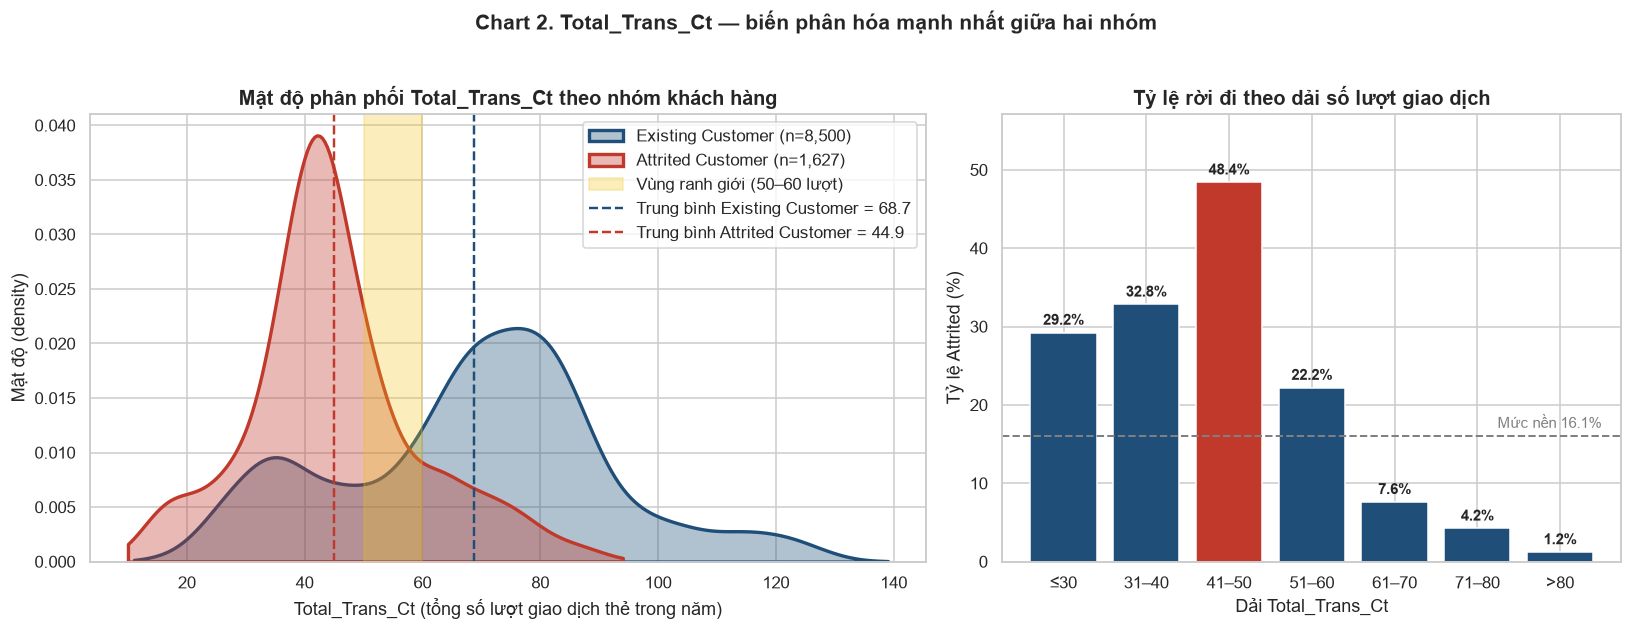

Total_Trans_Ct
≤30      29.2
31–40    32.8
41–50    48.4
51–60    22.2
61–70     7.6
71–80     4.2
>80       1.2

Thống kê Total_Trans_Ct theo nhóm:
                    count   mean    std   min   25%   50%   75%    max
Attrition_Flag                                                        
Existing Customer  8500.0  68.67  22.92  11.0  54.0  71.0  82.0  139.0
Attrited Customer  1627.0  44.93  14.57  10.0  37.0  43.0  51.0   94.0


In [5]:
# =====================================================================
# NHIỆM VỤ 4 - CHART 2: PHÂN PHỐI Total_Trans_Ct THEO NHÓM (KDE) + TỶ LỆ RỜI ĐI THEO DẢI
# =====================================================================
fig, axes = plt.subplots(1, 2, figsize=(15, 5.6), gridspec_kw={"width_ratios": [1.35, 1]})

# --- (a) KDE so sánh mật độ phân phối giữa hai nhóm ---
ax = axes[0]
for flag in (0, 1):
    sub = df.loc[df["Attrition_Flag"] == flag, "Total_Trans_Ct"]
    sns.kdeplot(sub, ax=ax, color=PAL[LABELS[flag]], fill=True, alpha=0.35, linewidth=2.2,
                cut=0, label=f"{LABELS[flag]} (n={len(sub):,})")
ax.axvspan(50, 60, color="#F1C40F", alpha=0.28, label="Vùng ranh giới (50–60 lượt)")

means = df.groupby("Attrition_Flag")["Total_Trans_Ct"].mean()
for flag, m in means.items():
    ax.axvline(m, color=PAL[LABELS[flag]], linestyle="--", linewidth=1.6,
               label=f"Trung bình {LABELS[flag]} = {m:.1f}")

ax.set_title("Mật độ phân phối Total_Trans_Ct theo nhóm khách hàng")
ax.set_xlabel("Total_Trans_Ct (tổng số lượt giao dịch thẻ trong năm)")
ax.set_ylabel("Mật độ (density)")
ax.legend(loc="upper right", frameon=True)

# --- (b) Tỷ lệ rời đi theo từng dải số lượt giao dịch ---
bins = [0, 30, 40, 50, 60, 70, 80, np.inf]
band_labels = ["≤30", "31–40", "41–50", "51–60", "61–70", "71–80", ">80"]
band = pd.cut(df["Total_Trans_Ct"], bins=bins, labels=band_labels)
rate = df.groupby(band, observed=True)["Attrition_Flag"].mean() * 100
overall = df["Attrition_Flag"].mean() * 100

ax = axes[1]
bar_colors = [COL_LEAVE if r == rate.max() else COL_STAY for r in rate.values]
ax.bar(rate.index.astype(str), rate.values, color=bar_colors, edgecolor="white")
for i, v in enumerate(rate.values):
    ax.text(i, v + 1, f"{v:.1f}%", ha="center", fontsize=10, fontweight="bold")
ax.axhline(overall, color="gray", linestyle="--", linewidth=1.3)
ax.text(len(rate) - 0.5, overall + 1, f"Mức nền {overall:.1f}%", ha="right", color="gray", fontsize=10)
ax.set_ylim(0, rate.max() * 1.18)
ax.set_title("Tỷ lệ rời đi theo dải số lượt giao dịch")
ax.set_xlabel("Dải Total_Trans_Ct")
ax.set_ylabel("Tỷ lệ Attrited (%)")

fig.suptitle("Chart 2. Total_Trans_Ct — biến phân hóa mạnh nhất giữa hai nhóm", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

# Số liệu đối chiếu
print(rate.round(1).to_string())
print("\nThống kê Total_Trans_Ct theo nhóm:")
print(df.groupby("Attrition_Flag")["Total_Trans_Ct"].describe().round(2).rename(index=LABELS).to_string())

### Diễn giải trực quan (Visual Interpretation) — Chart 2

**Hai phân phối tách biệt rõ rệt.**
- Nhóm **Attrited** có mật độ dồn mạnh quanh **khoảng 42 lượt/năm** (trung bình 44.9, trung vị 43), phân phối hẹp (std 14.6; 50% khách hàng nằm trong khoảng 37–51 lượt).
- Nhóm **Existing** có đỉnh chính quanh **khoảng 76 lượt/năm** (trung bình 68.7, trung vị 71), phân phối rộng (std 22.9; 50% khách hàng nằm trong khoảng 54–82 lượt). Đường mật độ nhóm này còn có một **gò phụ quanh 35 lượt**, trùng với vùng đỉnh của nhóm Attrited: đó là những khách hàng còn giữ thẻ nhưng hoạt động rất thấp.

**Điểm phân hóa và ranh giới nguy hiểm.**
- Hai đường mật độ **cắt nhau tại khoảng 57–58 lượt**: dưới mốc này mật độ nhóm Attrited cao hơn, trên mốc này nhóm Existing chiếm ưu thế. Phân vị thứ ba của nhóm Attrited (51 lượt) gần với phân vị thứ nhất của nhóm Existing (54 lượt), nghĩa là 75% khách hàng rời đi chỉ có tối đa 51 lượt, trong khi 75% khách hàng ở lại có từ 54 lượt trở lên. Vùng **50–60 lượt** (tô vàng) vì vậy là ranh giới chuyển pha giữa hai nhóm.
- Biểu đồ (b) cho thấy rủi ro **cao nhất ở dải 41–50 lượt** (tỷ lệ rời đi 48.4%, gấp khoảng 3 lần mức nền 16.1%). Sau đó tỷ lệ giảm nhanh: 22.2% ở dải 51–60, 7.6% ở dải 61–70 và chỉ còn 1.2% khi trên 80 lượt.
- Nếu lấy mốc 55 lượt/năm (khoảng 4–5 lượt mỗi tháng), 80.8% khách hàng rời đi nằm ở phía dưới mốc này so với 26.1% khách hàng ở lại. Tỷ lệ rời đi trong nhóm này là 37.2%, gấp khoảng 2.3 lần mức nền.

**Lưu ý.** Dải rất thấp (≤30 lượt) có tỷ lệ rời đi 29.2%, thấp hơn dải 41–50, vì gò phụ của nhóm Existing nói trên nằm ở vùng này. Nhóm khách hàng hoạt động rất thấp nhưng chưa rời đi cần được kiểm chứng thêm (họ là ai, vì sao vẫn giữ thẻ) và có thể là tệp cần chăm sóc sớm. Vì vậy không nên diễn giải rằng "giao dịch càng ít thì rủi ro càng tăng đơn điệu".

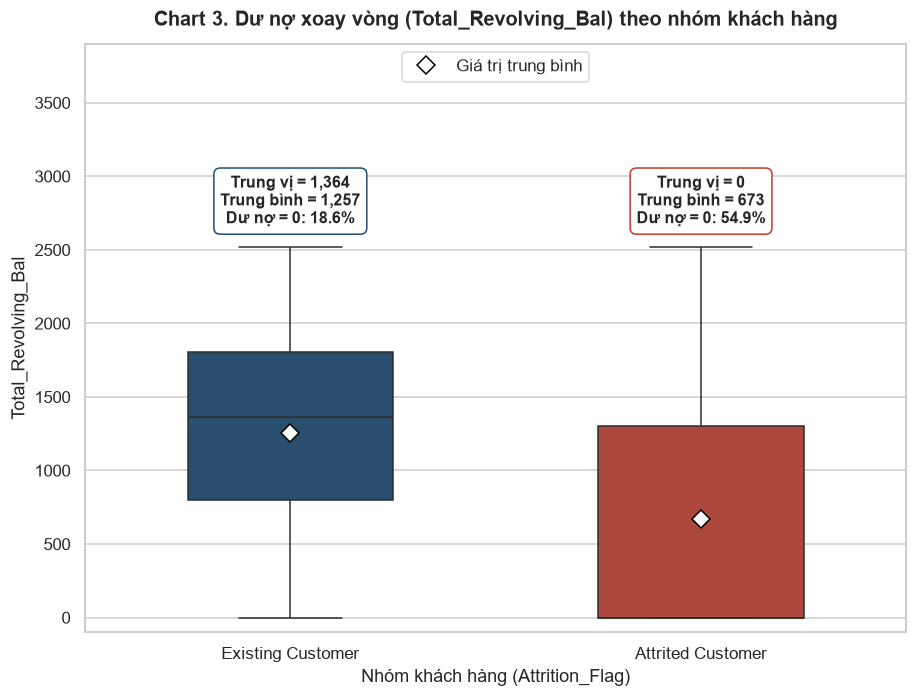

                    count    mean    std  min    25%     50%     75%     max
Group                                                                       
Attrited Customer  1627.0   672.8  921.4  0.0    0.0     0.0  1303.5  2517.0
Existing Customer  8500.0  1256.6  757.7  0.0  800.0  1364.0  1807.0  2517.0


In [6]:
# =====================================================================
# NHIỆM VỤ 4 - CHART 3: SO SÁNH DƯ NỢ XOAY VÒNG (BOXPLOT)
# =====================================================================
from matplotlib.lines import Line2D

fig, ax = plt.subplots(figsize=(8.5, 6.5))
sns.boxplot(
    data=plot_df, x="Group", y="Total_Revolving_Bal", order=HUE_ORDER,
    hue="Group", hue_order=HUE_ORDER, palette=PAL, dodge=False, width=0.5,
    showmeans=True,
    meanprops=dict(marker="D", markerfacecolor="white", markeredgecolor="black", markersize=8),
    flierprops=dict(markersize=3, alpha=0.4),
    ax=ax,
)
if ax.get_legend() is not None:
    ax.get_legend().remove()

# Chú thích số liệu phía trên mỗi hộp
for i, g in enumerate(HUE_ORDER):
    s = plot_df.loc[plot_df["Group"] == g, "Total_Revolving_Bal"]
    ax.text(i, 2650, f"Trung vị = {s.median():,.0f}\nTrung bình = {s.mean():,.0f}\nDư nợ = 0: {(s == 0).mean() * 100:.1f}%",
            ha="center", va="bottom", fontsize=10.5, fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor=PAL[g]))

ax.set_ylim(-100, 3900)
ax.set_title("Chart 3. Dư nợ xoay vòng (Total_Revolving_Bal) theo nhóm khách hàng", pad=12)
ax.set_xlabel("Nhóm khách hàng (Attrition_Flag)")
ax.set_ylabel("Total_Revolving_Bal")
ax.legend(handles=[Line2D([0], [0], marker="D", color="w", markerfacecolor="white",
                          markeredgecolor="black", markersize=8, label="Giá trị trung bình")],
          loc="upper center", frameon=True)
plt.tight_layout()
plt.show()

print(plot_df.groupby("Group")["Total_Revolving_Bal"].describe().round(1).to_string())

### Diễn giải trực quan (Visual Interpretation) — Chart 3

**Quan sát.**
- Nhóm **Existing**: dư nợ xoay vòng tập trung ở mức khá cao, trung vị 1364, 75% khách hàng có dư nợ không vượt quá 1807.
- Nhóm **Attrited**: trung vị **bằng 0** và phân vị thứ nhất cũng bằng 0, tức là hộp bị "chạm đáy". Có tới **54.9%** khách hàng rời đi có dư nợ xoay vòng bằng 0, so với 18.6% ở nhóm ở lại (gấp khoảng 3 lần). Dư nợ trung bình nhóm rời đi (673) chỉ bằng một nửa nhóm ở lại (1257).

**Diễn giải.** Dư nợ xoay vòng bằng 0 nghĩa là khách hàng không còn khoản dư nợ nào được chuyển sang kỳ sau, kết hợp với giao dịch thấp ở Chart 2 là dấu hiệu của hành vi **"ngừng sử dụng thẻ"**: thẻ dần nằm im trước khi khách hàng chính thức đóng thẻ. Đây là cách diễn giải phù hợp với dữ liệu, chưa phải kết luận nhân quả.

**Cảnh báo khi diễn giải.** Phân phối nhóm Attrited mang tính hai cực: một phần lớn dư nợ bằng 0, phần còn lại vẫn có dư nợ lên đến mức tối đa 2517, vì vậy độ lệch chuẩn nhóm này (921) cao hơn nhóm ở lại (758). Ngoài ra, 18.6% khách hàng ở lại cũng có dư nợ bằng 0 (ví dụ khách thanh toán đủ mỗi tháng). Dư nợ bằng 0 **không đủ để kết luận khách sẽ rời đi** và cần được kết hợp với `Total_Trans_Ct`.

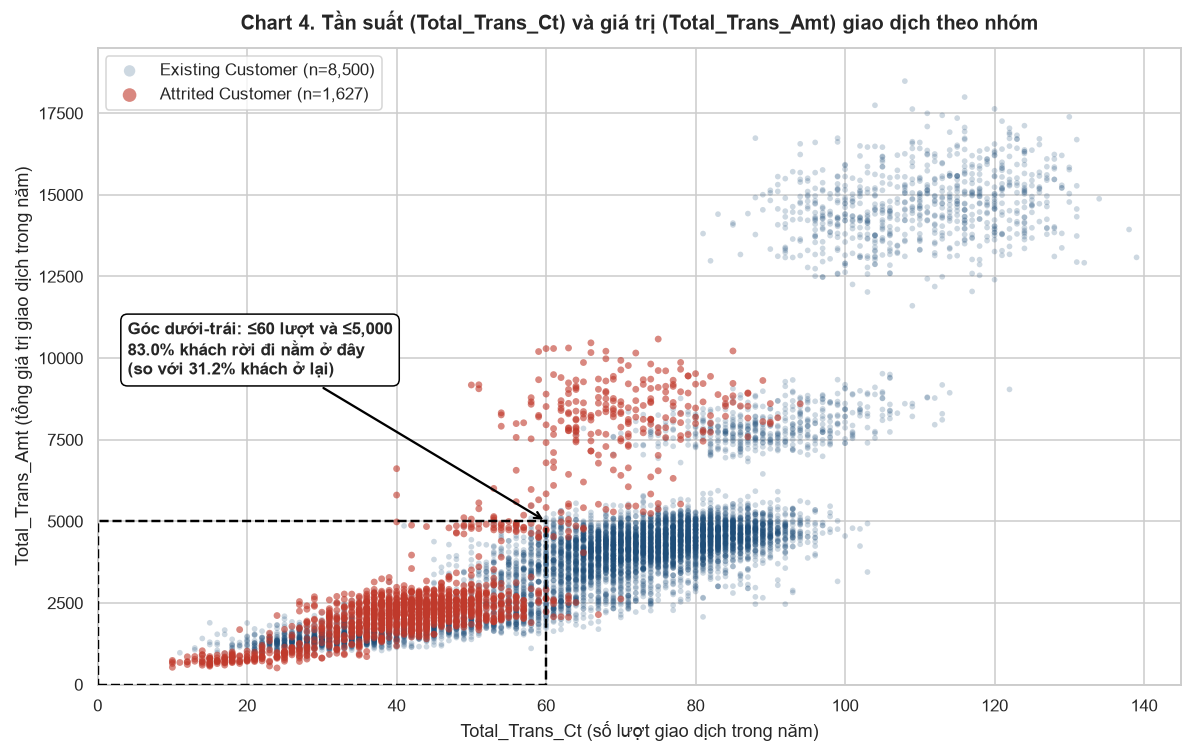

Tương quan Pearson giữa Total_Trans_Ct và Total_Trans_Amt: r = 0.81
Vùng góc dưới-trái chứa 4,002 khách hàng, trong đó tỷ lệ rời đi = 33.7% (mức nền 16.1%)
Khách rời đi có Total_Trans_Ct > 60: 14.5% | có Total_Trans_Amt > 8000: 9.4%


In [7]:
# =====================================================================
# NHIỆM VỤ 4 - CHART 4: TẦN SUẤT vs GIÁ TRỊ GIAO DỊCH (SCATTER PLOT)
# =====================================================================
from matplotlib.patches import Rectangle

CT_CUT, AMT_CUT = 60, 5000
in_zone = (df["Total_Trans_Ct"] <= CT_CUT) & (df["Total_Trans_Amt"] <= AMT_CUT)
share_att = in_zone[df["Attrition_Flag"] == 1].mean() * 100
share_stay = in_zone[df["Attrition_Flag"] == 0].mean() * 100
rate_zone = df.loc[in_zone, "Attrition_Flag"].mean() * 100

fig, ax = plt.subplots(figsize=(11, 7))
# Vẽ nhóm ở lại trước (mờ), nhóm rời đi sau (nổi bật) để không bị che khuất
for flag, alpha, size, z in [(0, 0.22, 14, 1), (1, 0.60, 20, 2)]:
    sub = df[df["Attrition_Flag"] == flag]
    ax.scatter(sub["Total_Trans_Ct"], sub["Total_Trans_Amt"], s=size, alpha=alpha,
               color=PAL[LABELS[flag]], edgecolors="none", zorder=z,
               label=f"{LABELS[flag]} (n={len(sub):,})")

ax.add_patch(Rectangle((0, 0), CT_CUT, AMT_CUT, fill=False, edgecolor="black",
                       linestyle="--", linewidth=1.6, zorder=3))
ax.annotate(
    f"Góc dưới-trái: ≤{CT_CUT} lượt và ≤{AMT_CUT:,}\n"
    f"{share_att:.1f}% khách rời đi nằm ở đây\n(so với {share_stay:.1f}% khách ở lại)",
    xy=(CT_CUT, AMT_CUT), xytext=(4, 9500), fontsize=11, fontweight="bold",
    arrowprops=dict(arrowstyle="->", color="black", lw=1.5),
    bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor="black"),
)
ax.set_xlim(0, 145)
ax.set_ylim(0, 19500)
ax.set_title("Chart 4. Tần suất (Total_Trans_Ct) và giá trị (Total_Trans_Amt) giao dịch theo nhóm", pad=12)
ax.set_xlabel("Total_Trans_Ct (số lượt giao dịch trong năm)")
ax.set_ylabel("Total_Trans_Amt (tổng giá trị giao dịch trong năm)")
ax.legend(loc="upper left", frameon=True, markerscale=2)
plt.tight_layout()
plt.show()

print(f"Tương quan Pearson giữa Total_Trans_Ct và Total_Trans_Amt: r = {df['Total_Trans_Ct'].corr(df['Total_Trans_Amt']):.2f}")
print(f"Vùng góc dưới-trái chứa {int(in_zone.sum()):,} khách hàng, trong đó tỷ lệ rời đi = {rate_zone:.1f}% (mức nền {df['Attrition_Flag'].mean() * 100:.1f}%)")
print(f"Khách rời đi có Total_Trans_Ct > {CT_CUT}: {(df.loc[df['Attrition_Flag'] == 1, 'Total_Trans_Ct'] > CT_CUT).mean() * 100:.1f}% | "
      f"có Total_Trans_Amt > 8000: {(df.loc[df['Attrition_Flag'] == 1, 'Total_Trans_Amt'] > 8000).mean() * 100:.1f}%")

### Diễn giải trực quan (Visual Interpretation) — Chart 4

**Quan sát.**
- `Total_Trans_Ct` và `Total_Trans_Amt` có **tương quan dương rất mạnh (r = 0.81)**: càng giao dịch nhiều lượt thì tổng chi tiêu càng lớn, các điểm dữ liệu dàn thành các dải đi lên từ trái sang phải.
- Nhóm **Attrited (đỏ) co cụm rõ ở góc dưới bên trái**: khu vực giao dịch ít và chi tiêu thấp (≤60 lượt và ≤5000). Vùng này chứa **83.0% khách hàng rời đi** nhưng chỉ chứa 31.2% khách hàng ở lại. Trong 4.002 khách hàng ở vùng này, tỷ lệ rời đi là **33.7%**, gấp khoảng 2.1 lần mức nền 16.1%.
- Nhóm **Existing (xanh)** trải rộng ra phía trên và bên phải, bao gồm cả những khách hàng giao dịch nhiều lượt với giá trị chi tiêu lớn. Vùng trên 80 lượt gần như chỉ có điểm xanh (tỷ lệ rời đi chỉ 1.2%).

**Diễn giải.** Việc kết hợp hai chiều (tần suất và giá trị) cho thấy khách hàng rời đi là những người **vừa ít dùng thẻ vừa chi tiêu thấp**: thẻ đã trở nên kém quan trọng với họ trước khi đóng thẻ.

**Ngoại lệ cần lưu ý.** Rời đi không chỉ xảy ra ở nhóm hoạt động thấp: 14.5% khách hàng rời đi có hơn 60 lượt giao dịch và 9.4% có tổng chi tiêu trên 8000. Trên biểu đồ còn thấy một cụm điểm đỏ thứ hai quanh 60–80 lượt với tổng chi tiêu khoảng 7500–10000. Đây là nhóm "rời đi dù đang hoạt động", có thể có nguyên nhân khác (ví dụ chuyển sang ưu đãi của ngân hàng khác), và cần được điều tra riêng, không thể chỉ dựa vào chỉ báo giao dịch thấp.

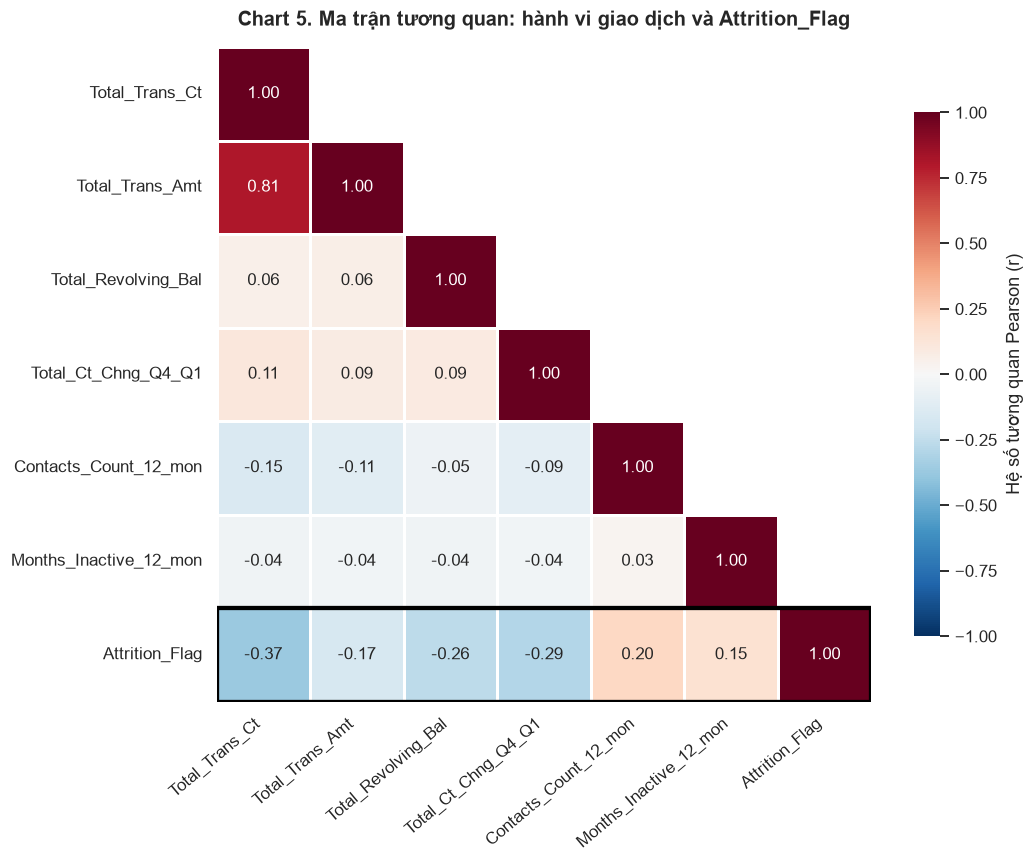

Tương quan của từng biến với Attrition_Flag (sắp theo giá trị tuyệt đối giảm dần):
Total_Trans_Ct           -0.371
Total_Ct_Chng_Q4_Q1      -0.290
Total_Revolving_Bal      -0.263
Contacts_Count_12_mon     0.204
Total_Trans_Amt          -0.169
Months_Inactive_12_mon    0.152

Cặp biến hành vi có tương quan mạnh nhất (theo |r|):
Total_Trans_Amt        Total_Trans_Ct     0.807
Contacts_Count_12_mon  Total_Trans_Ct    -0.152
                       Total_Trans_Amt   -0.113


In [8]:
# =====================================================================
# NHIỆM VỤ 4 - CHART 5: BẢN ĐỒ NHIỆT TƯƠNG QUAN (CORRELATION HEATMAP)
# =====================================================================
from matplotlib.patches import Rectangle

heat_cols = ["Total_Trans_Ct", "Total_Trans_Amt", "Total_Revolving_Bal",
             "Total_Ct_Chng_Q4_Q1", "Contacts_Count_12_mon", "Months_Inactive_12_mon",
             "Attrition_Flag"]
corr = df[heat_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)      # chỉ hiển thị nửa dưới ma trận

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0,
            linewidths=0.8, linecolor="white", square=True, annot_kws={"fontsize": 11},
            cbar_kws={"shrink": 0.8, "label": "Hệ số tương quan Pearson (r)"}, ax=ax)
n = len(heat_cols)
ax.grid(False)
ax.add_patch(Rectangle((0, n - 1), n, 1, fill=False, edgecolor="black", linewidth=2.8))   # nhấn mạnh hàng Attrition_Flag
ax.set_title("Chart 5. Ma trận tương quan: hành vi giao dịch và Attrition_Flag", pad=14)
plt.xticks(rotation=40, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Số liệu đối chiếu
print("Tương quan của từng biến với Attrition_Flag (sắp theo giá trị tuyệt đối giảm dần):")
r_target = corr["Attrition_Flag"].drop("Attrition_Flag")
print(r_target.reindex(r_target.abs().sort_values(ascending=False).index).round(3).to_string())

pairs = corr.drop(index="Attrition_Flag", columns="Attrition_Flag")
pairs = pairs.where(np.tril(np.ones(pairs.shape, dtype=bool), k=-1)).stack()
print("\nCặp biến hành vi có tương quan mạnh nhất (theo |r|):")
print(pairs.reindex(pairs.abs().sort_values(ascending=False).index).head(3).round(3).to_string())

### Diễn giải trực quan (Visual Interpretation) — Chart 5

**Tương quan của các biến hành vi với `Attrition_Flag` (hàng được khoanh đậm).** Xếp theo độ lớn của hệ số r:

| Biến | r | Hàm ý |
|---|---|---|
| `Total_Trans_Ct` | **−0.37** | Mạnh nhất. Giao dịch càng nhiều lượt thì càng ít khả năng rời đi |
| `Total_Ct_Chng_Q4_Q1` | −0.29 | Số lượt giao dịch quý 4 sụt so với quý 1 thì khả năng rời đi tăng |
| `Total_Revolving_Bal` | −0.26 | Dư nợ xoay vòng càng thấp thì càng dễ rời đi (khớp với Chart 3) |
| `Contacts_Count_12_mon` | +0.20 | Liên hệ chăm sóc khách hàng càng nhiều thì khả năng rời đi cao hơn |
| `Total_Trans_Amt` | −0.17 | Tương quan âm yếu hơn nhiều so với số lượt giao dịch |
| `Months_Inactive_12_mon` | +0.15 | Số tháng không hoạt động càng nhiều thì khả năng rời đi cao hơn |

**Điểm nhấn: tương quan âm của `Total_Trans_Ct`.** Đây là biến có tương quan âm mạnh nhất với việc rời bỏ (r = −0.37), nhất quán với các Chart 2 và 4. Đáng chú ý là `Total_Trans_Amt` có r = 0.81 với `Total_Trans_Ct` nhưng chỉ có r = −0.17 với `Attrition_Flag`: **mức độ gắn bó thể hiện qua tần suất sử dụng thẻ phản ánh rủi ro rời đi tốt hơn giá trị chi tiêu**.

**Cặp biến tương quan mạnh nhất** là `Total_Trans_Ct` – `Total_Trans_Amt` (r = 0.81). Các cặp còn lại đều yếu (|r| ≤ 0.15). Cặp 0.81 là dấu hiệu **đa cộng tuyến** cần lưu ý khi xây dựng mô hình tuyến tính/logistic (chọn một biến đại diện, hoặc dùng hiệu chỉnh L1/L2 (regularization) hay mô hình dựa trên cây).

**Cách đọc đúng.** Hệ số Pearson giữa biến liên tục và biến nhị phân đo quan hệ **tuyến tính, đơn biến**. |r| = 0.37 là mức trung bình, vì vậy cụm từ "mạnh nhất" chỉ có nghĩa so sánh tương đối giữa các biến. Tương quan **không chứng minh quan hệ nhân quả**.

In [9]:
# =====================================================================
# NHIỆM VỤ 5: NGHIÊN CỨU MỐI QUAN HỆ VÀ KẾT LUẬN NGHIỆP VỤ
# =====================================================================
beh_cols = ["Total_Trans_Ct", "Total_Trans_Amt", "Total_Revolving_Bal", "Total_Ct_Chng_Q4_Q1"]

# 5.1 So sánh giá trị trung bình các thuộc tính hành vi theo nhóm
means = df.groupby("Attrition_Flag")[beh_cols].mean().T
means.columns = [LABELS[c] for c in means.columns]
means["Chênh lệch"] = means["Attrited Customer"] - means["Existing Customer"]
means["% thay đổi"] = means["Chênh lệch"] / means["Existing Customer"] * 100
print("5.1 GIÁ TRỊ TRUNG BÌNH THEO NHÓM (Attrited so với Existing)")
display(means.round(2))

medians = df.groupby("Attrition_Flag")[beh_cols + ["Contacts_Count_12_mon", "Months_Inactive_12_mon"]].median().T
medians.columns = [LABELS[c] for c in medians.columns]
print("\nGiá trị TRUNG VỊ theo nhóm (bổ sung, ít bị ảnh hưởng bởi giá trị lệch):")
display(medians.round(2))

# 5.2 Top 5 biến tương quan mạnh nhất với Attrition_Flag
corr_target = (df.drop(columns="CLIENTNUM").select_dtypes("number")
                 .corr()["Attrition_Flag"].drop("Attrition_Flag"))
top5 = corr_target.reindex(corr_target.abs().sort_values(ascending=False).index).head(5)
top5_df = top5.to_frame("r (Pearson)")
top5_df["|r|"] = top5_df["r (Pearson)"].abs()
top5_df["Chiều tác động"] = np.where(top5_df["r (Pearson)"] > 0,
                                     "Dương (giá trị cao -> dễ rời đi hơn)",
                                     "Âm (giá trị cao -> ít rời đi hơn)")
top5_df.index.name = "Biến"
print("\n5.2 TOP 5 BIẾN TƯƠNG QUAN MẠNH NHẤT VỚI Attrition_Flag")
display(top5_df.round(3))

# 5.3 Tỷ lệ rời đi theo biến phân loại (để so sánh yếu tố nhân khẩu học với hành vi)
print("\n5.3 TỶ LỆ RỜI ĐI THEO BIẾN PHÂN LOẠI")
for col in ["Gender", "Card_Category", "Income_Category"]:
    t = df.groupby(col)["Attrition_Flag"].agg(["mean", "count"])
    t["mean"] = (t["mean"] * 100).round(2)
    t.columns = ["Tỷ lệ rời đi (%)", "Số khách hàng"]
    display(t.sort_values("Tỷ lệ rời đi (%)", ascending=False))

5.1 GIÁ TRỊ TRUNG BÌNH THEO NHÓM (Attrited so với Existing)


,Existing Customer,Attrited Customer,Chênh lệch,% thay đổi
Total_Trans_Ct,68.67,44.93,-23.74,-34.57
Total_Trans_Amt,4654.66,3095.03,-1559.63,-33.51
Total_Revolving_Bal,1256.60,672.82,-583.78,-46.46
Total_Ct_Chng_Q4_Q1,0.74,0.55,-0.19,-25.33



Giá trị TRUNG VỊ theo nhóm (bổ sung, ít bị ảnh hưởng bởi giá trị lệch):


,Existing Customer,Attrited Customer
Total_Trans_Ct,71.00,43.00
Total_Trans_Amt,4100.00,2329.00
Total_Revolving_Bal,1364.00,0.00
Total_Ct_Chng_Q4_Q1,0.72,0.53
Contacts_Count_12_mon,2.00,3.00
Months_Inactive_12_mon,2.00,3.00



5.2 TOP 5 BIẾN TƯƠNG QUAN MẠNH NHẤT VỚI Attrition_Flag


,r (Pearson),|r|,Chiều tác động
Biến,,,
Total_Trans_Ct,-0.371,0.371,Âm (giá trị cao -> ít rời đi hơn)
Total_Ct_Chng_Q4_Q1,-0.290,0.290,Âm (giá trị cao -> ít rời đi hơn)
Total_Revolving_Bal,-0.263,0.263,Âm (giá trị cao -> ít rời đi hơn)
Contacts_Count_12_mon,0.204,0.204,Dương (giá trị cao -> dễ rời đi hơn)
Avg_Utilization_Ratio,-0.178,0.178,Âm (giá trị cao -> ít rời đi hơn)



5.3 TỶ LỆ RỜI ĐI THEO BIẾN PHÂN LOẠI


,Tỷ lệ rời đi (%),Số khách hàng
Gender,,
F,17.36,5358
M,14.62,4769


,Tỷ lệ rời đi (%),Số khách hàng
Card_Category,,
Platinum,25.00,20
Gold,18.10,116
Blue,16.10,9436
Silver,14.77,555


,Tỷ lệ rời đi (%),Số khách hàng
Income_Category,,
$120K +,17.33,727
Less than $40K,17.19,3561
Unknown,16.82,1112
$80K - $120K,15.77,1535
$40K - $60K,15.14,1790
$60K - $80K,13.48,1402


## Kết luận và đề xuất (Insights & Conclusion)

### 1. Phát hiện then chốt
- **`Total_Trans_Ct` là chỉ báo phân hóa mạnh nhất.** Khách hàng rời đi giao dịch trung bình **44.9 lượt/năm**, thấp hơn khoảng 35% so với **68.7 lượt** của khách hàng ở lại. Đây cũng là biến có |r| lớn nhất với `Attrition_Flag` (r = −0.37).
- Các biến hành vi khác đều đồng thuận cùng hướng: tổng giá trị giao dịch thấp hơn (3095 so với 4655), dư nợ xoay vòng chỉ bằng khoảng một nửa (673 so với 1257, trung vị bằng 0 ở nhóm rời đi) và tỷ lệ số lượt giao dịch quý 4 so với quý 1 thấp hơn (0.55 so với 0.74).
- **Top 5 biến tương quan mạnh nhất với việc rời bỏ:** `Total_Trans_Ct` (−0.37), `Total_Ct_Chng_Q4_Q1` (−0.29), `Total_Revolving_Bal` (−0.26), `Contacts_Count_12_mon` (+0.20), `Avg_Utilization_Ratio` (−0.18). Cả năm biến đều thuộc nhóm hành vi sử dụng thẻ.
- **Hành vi quan trọng hơn nhân khẩu học.** Tỷ lệ rời đi giữa các nhóm giới tính hay thu nhập chỉ dao động quanh mức nền 16.1% (khoảng 13.5% đến 17.4%), trong khi theo số lượt giao dịch dao động từ 1.2% đến 48.4%.

### 2. Dấu hiệu nhận biết sớm khách hàng sắp rời bỏ
Một khách hàng nên được đưa vào danh sách theo dõi khi hội tụ nhiều dấu hiệu sau (ngưỡng mang tính mô tả, rút ra từ dữ liệu lịch sử):
1. **Số lượt giao dịch thấp**: dưới khoảng 55 lượt/năm, nguy cơ cao nhất ở dải 41–50 lượt (tỷ lệ rời đi 48.4%).
2. **Giao dịch sụt giảm giữa các quý**: `Total_Ct_Chng_Q4_Q1` quanh mức 0.5 (trung vị nhóm rời đi 0.53 so với 0.72).
3. **Dư nợ xoay vòng bằng 0** cùng với giao dịch thấp: thẻ có dấu hiệu "nằm im".
4. **Liên hệ chăm sóc khách hàng nhiều** (từ 3 lần trong 12 tháng, trung vị nhóm rời đi là 3 so với 2) và **không hoạt động từ 3 tháng** (trung vị 3 so với 2).

Từng dấu hiệu riêng lẻ chưa đủ kết luận (Chart 3 và Chart 4 đều có ngoại lệ); khả năng cảnh báo tăng khi kết hợp nhiều dấu hiệu.

### 3. Đề xuất hành động nghiệp vụ
- Theo dõi hàng tháng `Total_Trans_Ct` và tỷ lệ thay đổi giữa các quý, tự động gắn cờ khách hàng chạm ngưỡng.
- Với nhóm bị gắn cờ, ưu tiên chăm sóc chủ động (gọi điện, ưu đãi hoàn tiền hoặc điểm thưởng gắn với giao dịch, chương trình kích hoạt lại thẻ) trước khi khách hàng chính thức đóng thẻ.

### 4. Hướng xây dựng mô hình dự báo (Machine Learning) cho giai đoạn tiếp theo
- **Bài toán:** phân loại nhị phân dự báo `Attrition_Flag`. Loại `CLIENTNUM` khỏi tập đặc trưng.
- **Chuẩn bị dữ liệu:** mã hóa biến phân loại (`Income_Category` và `Education_Level` có thứ tự; `Gender`, `Marital_Status`, `Card_Category` dùng one-hot), quyết định cách xử lý nhãn `Unknown`, kiểm tra đa cộng tuyến (VIF) vì cặp `Total_Trans_Ct` – `Total_Trans_Amt` có r = 0.81.
- **Chia dữ liệu:** train/test **phân tầng (stratified)** theo `Attrition_Flag` để giữ tỷ lệ 83.9 : 16.1; mọi biến đổi (scaling, cân bằng lớp) chỉ fit trên tập train để tránh rò rỉ dữ liệu.
- **Xử lý mất cân bằng:** `class_weight="balanced"` hoặc SMOTE (chỉ áp dụng trên tập train).
- **Mô hình:** bắt đầu với Logistic Regression làm baseline, sau đó thử Random Forest và Gradient Boosting (XGBoost/LightGBM); tinh chỉnh bằng cross-validation phân tầng.
- **Đánh giá:** ưu tiên Recall, Precision, F1, PR-AUC và ROC-AUC trên lớp Attrited, không chỉ Accuracy; chọn ngưỡng phân loại theo chi phí nghiệp vụ. Giải thích mô hình bằng feature importance và SHAP để đối chiếu với các phát hiện EDA.

### 5. Hạn chế cần ghi nhận
- Đây là phân tích tương quan trên dữ liệu cắt ngang, **không chứng minh nhân quả**. Các biến giao dịch được đo trong cùng 12 tháng với việc rời đi nên giao dịch giảm có thể là hệ quả của quyết định rời đi chứ không chỉ là nguyên nhân. Muốn dự báo sớm thực sự cần dữ liệu theo chuỗi thời gian trước thời điểm đóng thẻ.
- Hạng thẻ Gold (116 khách hàng) và Platinum (20 khách hàng) có cỡ mẫu nhỏ nên kết luận theo hạng thẻ kém tin cậy.